In [1]:
import numpy as np
from matplotlib import pyplot as plt

from primus_paleo import FluxHistory, Paleodetector, slice_spectrum_etch

In [2]:
# Local time t [kyr] = 5970 - age [ka]: t = 0 at 5.97 Ma (base of the Main Halite), 640 at 5.33 Ma, 5970 today.
# Brine/water depth above the depositional surface (the free parameters of the scenario):
total_age_kyr_A = 5970
flood_time_A = 640.

D0      = 1000.   # at 5.97 Ma, when the sample forms                      [m]
D1      = 800.    # at 5.60 Ma, end of stage 1, before the drawdown        [m]
D_acme  = 300.    # at 5.55 Ma, stage-2 drawdown acme; kept until 5.33 Ma  [m]
D_flood = 2000.   # just after the Zanclean reflooding, 5.33 Ma            [m]
D_today = 1644.   # today (Leviathan-1 water depth)                        [m]

deep_water_base = {
    "initial_depth": D0,
    "initial_density_g_cm3": 1.2,
    "start_time_continuous_kyr": [0.,    0.,              370.,                 370.,  640.,   640.],
    "end_time_continuous_kyr":   [370.,  370.,            420.,                 640.,  5970.,  5970.],
    "rate_continuous":           [2.6,   (D1 - D0) / 370, (D_acme - D1) / 50,   2.7,   0.085,  (D_today - D_flood) / 5330],
    "density_continuous_g_cm3":  [2.16,  1.2,             1.2,                  2.3,   2.1,    1.03],
    "time_discrete_kyr":      [flood_time_A,     flood_time_A],
    "overburden_discrete":    [-D_acme,  D_flood],
    "density_discrete_g_cm3": [1.2,      1.03],
}


In [3]:
total_age_kyr_B = 5600
flood_time_B = 270

z_floor = 2000.    # depth of the brine surface below global sea level during the desiccation [m]
air_mwe = 10.33 * (np.exp(z_floor / 8400.) - 1.0)   # extra atmosphere above it, ~2.8 m.w.e. for 2 km
D_brine = 5.       # brine depth during the halite deposition, 5.60-5.55 Ma [m]
D_lake  = 20.      # lake depth during stage 3, Upper Gypsum / Lago-Mare, 5.55-5.33 Ma [m]
D_flood = 2000.    # seawater depth just after the Zanclean reflooding, 5.33 Ma [m]
D_today = 1644.    # today (Leviathan-1 water depth) [m]
H_halite, H_IE, H_AE, H_PQ = 960., 480., 230., 450.   # Main Halite, Interbedded Ev., Argillaceous Ev., Plio-Quaternary [m]

desiccation_base = {
    "initial_depth": air_mwe + 1.2 * D_brine, "initial_density_g_cm3": 1.0,   # extra air + brine, in m.w.e.
    "start_time_continuous_kyr": [0.,              50.,           180.,         270.,           270.],
    "end_time_continuous_kyr":   [50.,             180.,          270.,         5600.,          5600.],
    "rate_continuous":           [H_halite / 50.,  H_IE / 130.,   H_AE / 90.,   H_PQ / 5330.,   (D_today - D_flood) / 5330.],
    "density_continuous_g_cm3":  [2.16,            2.3,           2.3,          2.1,            1.03],
    "time_discrete_kyr":      [50.,              flood_time_B,    flood_time_B,      flood_time_B],
    "overburden_discrete":    [D_lake - D_brine, -D_lake,  -air_mwe,  D_flood],
    "density_discrete_g_cm3": [1.2,              1.2,      1.0,       1.03],
}

In [4]:
mineral_name =  "Halite"

sample_area_cm2 = 1*2

In [5]:
flux_history_simple = FluxHistory()
flux_history_SN100 = FluxHistory(events=[{"start_time_kyr":- total_age_kyr_B - 25., "template": {"kind":"SN", "distance_pc": 100.}}])

/home/cgalelli/miniconda3/envs/paleo/lib/python3.14/site-packages/crflux/models.py:224: RuntimeWarning: invalid value encountered in divide
  p_frac = np.where(total > 0, p_flux / total, 0.0)


In [6]:
mineral = Paleodetector(mineral_name, total_age_kyr=total_age_kyr_B, overburden_history=desiccation_base, flux_history=flux_history_simple)
mineral_deepwater = Paleodetector(mineral_name, total_age_kyr=total_age_kyr_A, overburden_history=deep_water_base, flux_history=flux_history_simple)


Interpolating overburden history...
Time grid: 629 nodes over 0-5600 kyr (105 uniform and breakpoint nodes, 524 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Halite, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 171.9 GeV in 90 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondar

In [7]:
x_bins, fission_tracks = mineral.integrate_fission_spectrum()
x_bins, neutron_tracks = mineral.integrate_background_neutron_spectrum()
x_bins, fission_tracks_deepwater = mineral_deepwater.integrate_fission_spectrum()
x_bins, neutron_tracks_deepwater = mineral_deepwater.integrate_background_neutron_spectrum()

Calculating spontaneous fission background...
Processing background neutron tracks from fission_n
Processing background neutron tracks from alpha_n
Calculating spontaneous fission background...
Processing background neutron tracks from fission_n
Processing background neutron tracks from alpha_n


In [8]:
x_bins, tracks_simple = mineral.integrate_all_particles(exposure_window_kyr=[0., flood_time_B])
x_bins, tracks_simple_deepwater = mineral_deepwater.integrate_all_particles(exposure_window_kyr=[0., flood_time_A])

100%|██████████| 5/5 [01:12<00:00, 14.48s/it]


In [9]:
x_bins, tracks_post = mineral.integrate_all_particles(exposure_window_kyr=[flood_time_B, total_age_kyr_B])

100%|██████████| 5/5 [00:29<00:00,  6.00s/it]


In [10]:
x_bins, tracks_SN100 = mineral.integrate_all_particles(exposure_window_kyr=[0., flood_time_B], flux_history=flux_history_SN100)

Time grid: 715 nodes over 0-5600 kyr (342 uniform and breakpoint nodes, 373 added where the overburden or flux change; 1 flux events, 0 excursions)


100%|██████████| 5/5 [01:32<00:00, 18.44s/it]


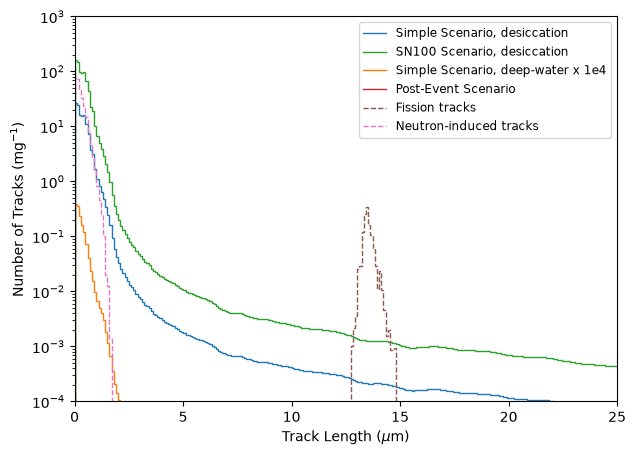

In [11]:
fig, ax = plt.subplots(figsize=[7, 5])

spec = 'total'

ax.stairs(tracks_simple[spec], x_bins/1000, label=f'Simple Scenario, desiccation')
ax.stairs(tracks_SN100[spec], x_bins/1000, color='C2', label='SN100 Scenario, desiccation')

ax.stairs(tracks_simple_deepwater[spec]*1e4, x_bins/1000, label=f'Simple Scenario, deep-water x 1e4')


ax.stairs(tracks_post[spec], x_bins/1000, color='C3', label='Post-Event Scenario')
   
ax.stairs(fission_tracks, x_bins/1000, color='C5', linestyle='dashed', label="Fission tracks")
ax.stairs(neutron_tracks, x_bins/1000, color='C6', linestyle='dashed', label="Neutron-induced tracks")

ax.set_xlabel(r"Track Length ($\mu$m)")
ax.set_ylabel(r"Number of Tracks (mg$^{-1}$)")
ax.set_yscale("log")
ax.set_ylim(1e-4, 1e3)
ax.set_xlim(0, 25)
ax.legend(fontsize='small')
plt.show()

In [12]:
print(f"Desiccation scenario vs deep-water scenario: {np.sum(tracks_simple[spec])/np.sum(tracks_simple_deepwater[spec])}")

Desiccation scenario vs deep-water scenario: 890708.0752166613


In [13]:
sliced_bkg = slice_spectrum_etch(neutron_tracks + fission_tracks, sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral.config["density_g_cm3"], etch_type='HF')

sliced_simple = slice_spectrum_etch(tracks_simple[spec], sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral.config["density_g_cm3"], etch_type='HF')

sliced_SN100 = slice_spectrum_etch(tracks_SN100[spec], sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral.config["density_g_cm3"], etch_type='HF')

sliced_simple_deepwater = slice_spectrum_etch(tracks_simple_deepwater[spec], sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral.config["density_g_cm3"], etch_type='HF')

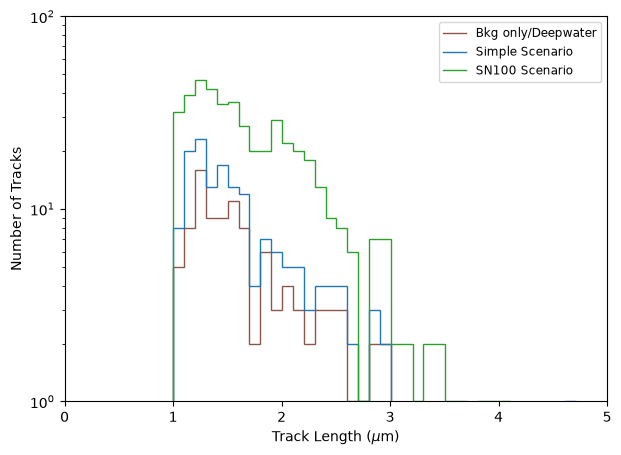

In [14]:
fig, ax = plt.subplots(figsize=[7, 5])

ax.stairs(sliced_bkg, x_bins/1000, color='C5', label=f'Bkg only/Deepwater')

ax.stairs(sliced_simple + sliced_bkg, x_bins/1000, color ='C0', label=f'Simple Scenario')
ax.stairs(sliced_SN100 + sliced_bkg, x_bins/1000, color='C2',label='SN100 Scenario')
 
ax.set_xlabel(r"Track Length ($\mu$m)")
ax.set_ylabel(r"Number of Tracks")
ax.set_yscale("log")
ax.set_ylim(1e0, 1e2)
ax.set_xlim(0, 5)
ax.legend(fontsize='small')
plt.show()